In [30]:
import pandas as pd
df=pd.read_csv('ecommerce.csv')
print(df.shape)
print(df.head())
print(df.info())
print(df.describe())

(138116, 46)
     order_id  order_date order_time order_status sales_channel  customer_id  \
0  ORD-301242  2023-11-06   16:37:47    Completed    Mobile App  CUST-003102   
1  ORD-773460  2025-12-24   01:22:36    Completed       Website  CUST-003124   
2  ORD-449374  2021-07-05   14:24:21    Completed    Mobile App  CUST-012496   
3  ORD-567636  2023-01-21   07:20:26    Completed  Social Media  CUST-023928   
4  ORD-820028  2022-05-13   09:46:21    Completed  Social Media  CUST-012730   

    customer_name  customer_age  gender customer_segment customer_type  \
0    Jasmine Ryan            55    Male         Consumer         Loyal   
1     Scott Chase            26    Male          Premium         Loyal   
2    Marc Wheeler            69  Female          Premium         Loyal   
3  Jennifer Smith            65    Male         Consumer         Loyal   
4    Jessica Wang            34  Female         Consumer         Loyal   

      customer_city     customer_state customer_country regio

In [31]:
pd.set_option('display.max_columns', None)

print(df.isnull().sum())
print(df.duplicated().sum())
print(df['order_date'].dtype)

order_id                         0
order_date                       0
order_time                       0
order_status                     0
sales_channel                    0
customer_id                      0
customer_name                    0
customer_age                     0
gender                           0
customer_segment                 0
customer_type                    0
customer_city                    0
customer_state                   0
customer_country                 0
region                           0
customer_postal_code             0
payment_method                   0
payment_status                   0
currency                         0
shipping_method                  0
warehouse                        0
delivery_days                24557
estimated_delivery_days      24557
delivery_status                  0
return_status               128654
return_reason               128654
customer_rating              24557
review_sentiment             24557
customer_review     

In [32]:
#1.reason check
print(df[df['delivery_days'].isnull()]['order_status'].value_counts())
df['return_status']=df['return_status'].fillna('Not Returned')
df['order_date']=pd.to_datetime(df['order_date'])
print(df['order_date'].dtype)

order_status
Returned     9462
Cancelled    8398
Pending      6697
Name: count, dtype: int64
datetime64[us]


In [33]:
#sales analysis
completed=df[df['order_status']=='Completed']
print(df.shape)
print(completed.shape)

(138116, 46)
(113559, 46)


In [34]:
#groupby
print(completed.groupby('sales_channel')[['net_sales','profit']].sum())

                 net_sales       profit
sales_channel                          
Marketplace    21775779.70   8983667.03
Mobile App     57617393.09  23877394.95
Social Media   14457477.56   6009447.97
Website        50345188.15  20887959.08


In [35]:
g=completed.groupby('sales_channel')[['net_sales','profit']].sum()
g['margin_%'] =g['profit']/g['net_sales']*100
print(g)
print(completed.groupby(completed['order_date'].dt.year)['net_sales'].sum())

                 net_sales       profit   margin_%
sales_channel                                     
Marketplace    21775779.70   8983667.03  41.255317
Mobile App     57617393.09  23877394.95  41.441297
Social Media   14457477.56   6009447.97  41.566366
Website        50345188.15  20887959.08  41.489485
order_date
2021    29303670.50
2022    28708801.55
2023    28920005.11
2024    28689564.03
2025    28573797.31
Name: net_sales, dtype: float64


In [36]:
print(completed['order_date'].max())
print(completed.groupby(completed['order_date'].dt.year)['order_id'].count())

2025-12-31 00:00:00
order_date
2021    22835
2022    22659
2023    22722
2024    22670
2025    22673
Name: order_id, dtype: int64


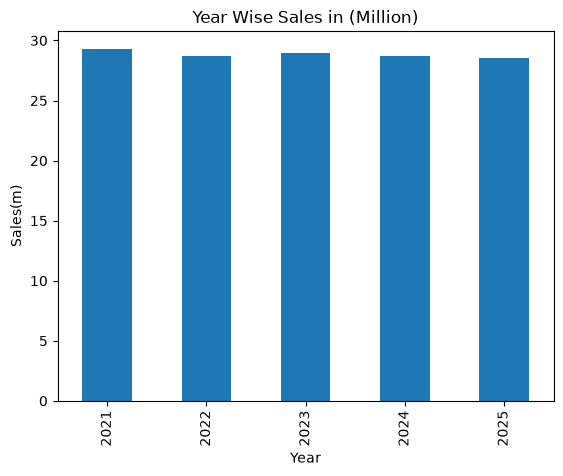

In [37]:
import matplotlib.pyplot as plt
sales=completed.groupby(completed['order_date'].dt.year)['net_sales'].sum()/1_000_000

sales.plot(kind='bar')
plt.title('Year Wise Sales in (Million)')
plt.xlabel('Year')
plt.ylabel('Sales(m)')
plt.show()

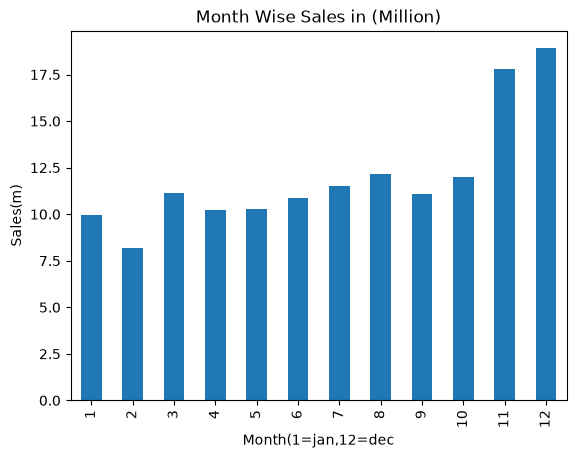

In [38]:
monthly=completed.groupby(completed['order_date'].dt.month)['net_sales'].sum()/1_000_000
monthly.plot(kind='bar')
plt.title('Month Wise Sales in (Million)')
plt.xlabel('Month(1=jan,12=dec')
plt.ylabel('Sales(m)')
plt.show()

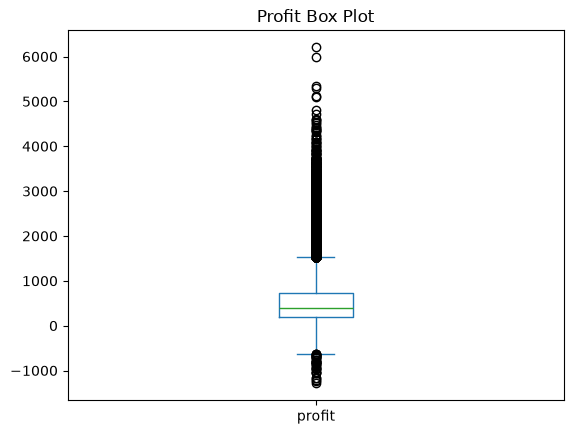

count    113559.000000
mean        526.232787
std         489.386886
min       -1281.590000
25%         182.555000
50%         393.180000
75%         721.950000
max        6209.490000
Name: profit, dtype: float64
1229


In [28]:
completed['profit'].plot(kind='box')
plt.title('Profit Box Plot')
plt.show()
print(completed['profit'].describe())
print((completed['profit']<0).sum())

In [29]:
p=completed['profit']
q1=p.quantile(0.25)
q3=p.quantile(0.75)
iqr=q3-q1
high =p > q3 + 1.5*iqr
low =p < q1 - 1.5*iqr
print(p.median())
print((p<0).sum())
print(high.sum(),low.sum())

393.18
1229
5185 38


In [39]:
print(df.columns.to_list())
r=completed.groupby('region')[['net_sales','profit']].sum()
print(r.sort_values('net_sales',ascending=False))

['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count']
           net_sales       profit
region                           
South    45373793.39  18357466.87
Central  30047180.00  12102279.56
West     28415068.48  12359083.04
East     220336

In [40]:
sales = completed.groupby(completed['order_date'].dt.year)['net_sales'].sum()
orders = completed.groupby(completed['order_date'].dt.year)['order_id'].count()
print(sales / orders)

order_date
2021    1283.278761
2022    1266.993316
2023    1272.775509
2024    1265.529953
2025    1260.256574
dtype: float64


# E-commerce Sales Analysis

## Objective
Analyze order data to understand sales performance by channel and over time.

## Data
- 138,116 orders and 46 columns (Kaggle e-commerce dataset)
- No duplicate rows
- Missing delivery days were limited to Cancelled, Pending and Returned orders, so they were left as null
- Empty return status values were filled with "Not Returned"
- Analysis uses Completed orders only (113,559), since the other statuses did not generate sales

## Key Findings
1. **Mobile App is the top channel** with 57.6M in sales, followed by Website (50.3M), Marketplace (21.8M) and Social Media (14.5M).
2. **Profit margin is about 41% across all channels.** Mobile App leads because of order volume, not better margins.
3. **Sales were flat from 2021 to 2025**, moving from 29.3M to 28.6M (a 2.5% drop). Order count fell only 0.7%, so most of the drop came from a lower average order value.
4. **Profit has a long upper tail:** a small number of orders earn far above the typical profit, and a few orders make a loss.

## Tools
Python, pandas, matplotlib